# Núcleo 1 — Serie histórica de coparticipación (2003-2025)

Acá miro cómo evolucionó la coparticipación federal que recibieron las provincias
argentinas, con foco en Córdoba: en pesos constantes (deflactados por IPC) y, para saber
si eso es mucho o poco, por habitante y como porcentaje del PIB.

El rango cubierto es 2003-2025 — lo amplié desde 2016-2025 al conseguir una fuente de
IPC confiable para 2003-2015 (Fundación Norte y Sur / Orlando Ferreres). No llega a
1990, que era la idea original, porque no existe una fuente de montos nominales de
coparticipación para 1990-2002; el detalle de ese empalme y de esa limitación está en
`docs/methodology.md`.

Defino "coparticipación" como la coparticipación Ley 23.548 bruta (incluida la parte que
la Ley 26.075 afecta a Financiamiento Educativo), más la compensación del Consenso Fiscal
(Ley 27.429, desde 2018), más, hasta 2017, las asignaciones específicas de Ganancias que
el Consenso Fiscal pasó a repartir por la Ley 23.548. Con esa definición la serie no
tiene quiebres cuando Hacienda cambia la forma de informar, y coincide con lo que
registra la propia Córdoba (Núcleo 4). Dejo afuera otros regímenes de Recursos de Origen
Nacional como el IVA de la Ley 23.966, Bienes Personales o combustibles. El porqué de
cada decisión está en `docs/methodology.md`.

Trabajo sobre `data/processed/coparticipacion_real.csv`, generado por
`scripts/process_coparticipacion.py`, y sobre `coparticipacion_por_habitante.csv` y
`coparticipacion_agregada.csv` (población estimada entre censos y PIB del INDEC),
generados por `scripts/build_coparticipacion_pib_poblacion.py`.

In [1]:
import sys

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path

# Paleta y estilo (validados con el validador de la skill de dataviz del proyecto:
# 4 colores categóricos en orden fijo, pasan los chequeos de daltonismo para líneas).
COLOR_CORDOBA = "#2a78d6"      # slot 1 - azul
COLOR_BUENOS_AIRES = "#eb6834" # slot 2 - naranja
COLOR_SANTA_FE = "#1baf7a"     # slot 3 - aqua
COLOR_MENDOZA = "#eda100"      # slot 4 - amarillo

INK_PRIMARY = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
GRID_COLOR = "#e1e0d9"
SURFACE = "#fcfcfb"

plt.rcParams.update({
    "font.family": "sans-serif",
    "axes.edgecolor": GRID_COLOR,
    "axes.labelcolor": INK_SECONDARY,
    "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED,
    "text.color": INK_PRIMARY,
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
})

BASE_DIR = Path("..").resolve() if Path("../data").exists() else Path(".").resolve()
FIGURES_DIR = BASE_DIR / "output" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(BASE_DIR / "scripts"))
from build_coparticipacion_pib_poblacion import descomponer  # noqa: E402

df = pd.read_csv(BASE_DIR / "data" / "processed" / "coparticipacion_real.csv")
# El CSV trae los montos reales en pesos de 2016. Para los gráficos los paso a pesos de
# 2025, una unidad más fácil de dimensionar: mismo IPC, solo cambia el año de referencia.
ipc_2025 = df.loc[df["anio"] == 2025, "ipc_promedio_anual"].iloc[0]
df["real_miles_millones_2025"] = df["monto_nominal"] * ipc_2025 / df["ipc_promedio_anual"] / 1e3
por_habitante = pd.read_csv(BASE_DIR / "data" / "processed" / "coparticipacion_por_habitante.csv")
agregada = pd.read_csv(BASE_DIR / "data" / "processed" / "coparticipacion_agregada.csv")


def ar(valor, decimales=2):
    """Formato argentino: coma decimal, punto de miles."""
    return f"{valor:,.{decimales}f}".replace(",", "X").replace(".", ",").replace("X", ".")


def pesos_por_habitante(miles):
    """Etiqueta en miles de pesos, o en millones desde $1 millón."""
    return f"${ar(miles / 1e3)} millones" if miles >= 1e3 else f"${ar(miles, 0)} mil"


df.head()

,provincia,anio,monto_nominal,ipc_promedio_anual,monto_real_base2016,real_miles_millones_2025
0,Buenos Aires,2003,3534.2179,7.653077,42090.902105,4140.607000
1,Buenos Aires,2004,5063.0036,7.991016,57748.042701,5680.846403
2,Buenos Aires,2005,6177.2050,8.761483,64260.697259,6321.515567
3,Buenos Aires,2006,7528.0907,9.716292,70617.984679,6946.900804
4,Buenos Aires,2007,9841.3698,11.106101,80765.325161,7945.124812


## 1. Verificación rápida de los datos

Espero 552 filas: 24 jurisdicciones (23 provincias + CABA) × 23 años (2003-2025).
`monto_nominal` está en millones de pesos corrientes; `monto_real_base2016`, en
millones de pesos constantes de 2016 (promedio del año). Para los gráficos uso
`real_miles_millones_2025`: el mismo monto real, en miles de millones de pesos de 2025.

In [2]:
print(f"Filas: {len(df)}  |  Provincias: {df['provincia'].nunique()}  |  Años: {df['anio'].min()}-{df['anio'].max()}")
assert len(df) == 552, "Se esperaban 552 filas (24 jurisdicciones x 23 años)"
df.describe()


Filas: 552  |  Provincias: 24  |  Años: 2003-2025


,anio,monto_nominal,ipc_promedio_anual,monto_real_base2016,real_miles_millones_2025
count,552.000000,5.520000e+02,552.000000,552.000000,552.000000
mean,2014.000000,2.306570e+05,861.692484,20120.019931,1979.266093
std,6.639266,8.562244e+05,2171.958535,20296.904784,1996.666781
min,2003.000000,1.798141e+02,7.653077,2141.502843,210.665992
25%,2008.000000,2.038377e+03,13.653147,9169.869508,902.067287
50%,2014.000000,9.658495e+03,51.931048,14816.231858,1457.516714
75%,2020.000000,6.766536e+04,330.541683,22240.577344,2187.871621
max,2025.000000,1.299461e+07,8966.166533,148263.193119,14585.090471


## 2. Evolución real de la coparticipación de Córdoba

En pesos constantes de 2025, para sacar el efecto de la inflación y ver si a la
provincia le quedó más o menos poder de compra a lo largo del tiempo.

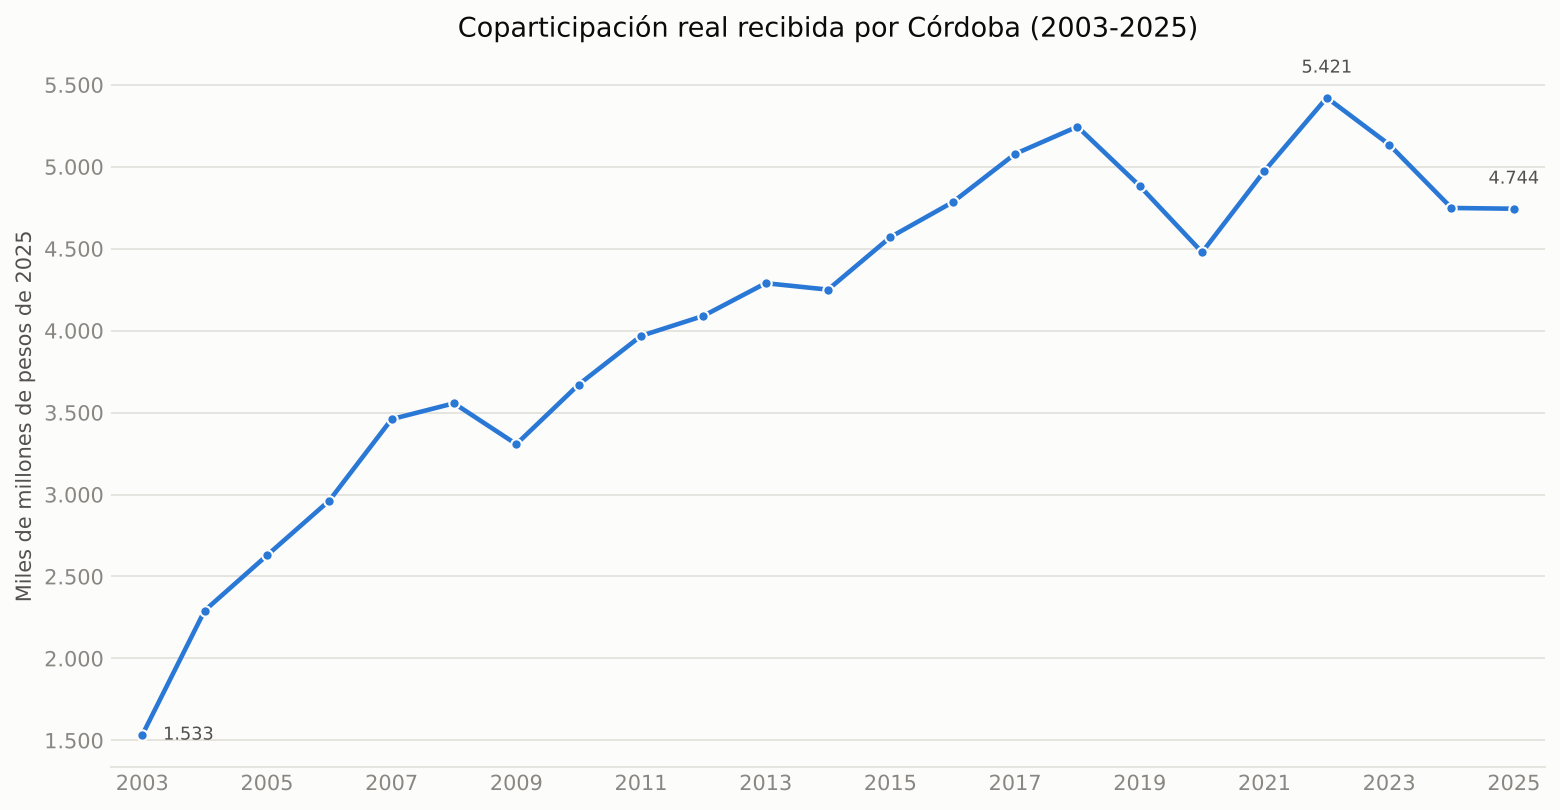

In [3]:
cordoba = df[df["provincia"] == "Córdoba"].sort_values("anio")

fig, ax = plt.subplots(figsize=(10.5, 5.5), dpi=150)
ax.plot(
    cordoba["anio"], cordoba["real_miles_millones_2025"],
    color=COLOR_CORDOBA, linewidth=2.2, marker="o", markersize=5,
    markerfacecolor=COLOR_CORDOBA, markeredgecolor=SURFACE, markeredgewidth=1,
)

# Etiquetas directas selectivas: primer punto, mínimo, máximo y último punto.
idx_max = cordoba["real_miles_millones_2025"].idxmax()
idx_min = cordoba["real_miles_millones_2025"].idxmin()
for idx in sorted(set([cordoba.index[0], idx_min, idx_max, cordoba.index[-1]])):
    row = cordoba.loc[idx]
    ax.annotate(
        f"{row['real_miles_millones_2025']:,.0f}".replace(",", "."),
        (row["anio"], row["real_miles_millones_2025"]),
        textcoords="offset points",
        xytext=((10, 0) if idx == cordoba.index[0] else (0, 10)),
        ha=("left" if idx == cordoba.index[0] else "center"),
        va=("center" if idx == cordoba.index[0] else "bottom"),
        fontsize=8.5, color=INK_SECONDARY,
    )

ax.set_title("Coparticipación real recibida por Córdoba (2003-2025)", fontsize=13, color=INK_PRIMARY, pad=14)
ax.set_ylabel("Miles de millones de pesos de 2025", fontsize=10)
ax.set_xlabel("")
ax.set_xlim(2002.5, 2025.5)
ax.set_xticks(range(2003, 2026, 2))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", ".")))
ax.grid(axis="y", color=GRID_COLOR, linewidth=0.8)
ax.set_axisbelow(True)
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_color(GRID_COLOR)
ax.tick_params(axis="both", length=0)
plt.setp(ax.get_xticklabels(), rotation=0)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "cordoba_evolucion_real_2003_2025.png", dpi=300, facecolor=SURFACE)
plt.show()

La coparticipación real de Córdoba creció fuerte entre 2003 y 2008 (recuperación
pos-crisis 2001-2002), cayó en 2009 (crisis financiera internacional), volvió a crecer
hasta 2013 y tuvo una leve baja en 2014. Entre 2015 y 2018 sigue subiendo, cae en
2019-2020 (recesión y pandemia), llega a su punto más alto de toda la serie en 2022
(\$5,42 billones de 2025) y vuelve a caer en 2023-2025, consistente con el ajuste fiscal
de esos años a nivel nacional. En 2025 (\$4,74 billones) queda 12,5% por debajo del pico
de 2022, más o menos en el nivel de 2016.

Contra 2003, 2025 es 3,1 veces más, pero ese múltiplo exagera: 2003 es el piso de la
crisis, y solo en 2004 la serie subió 50% real. Contra 2004, la suba es de 2,1 veces. Y
como la población también creció, la pregunta que importa es cuánto creció por
habitante y contra el tamaño de la economía (secciones 4 y 5).

## 3. Comparativo: Córdoba vs. provincias de referencia

La comparo contra Buenos Aires, Santa Fe y Mendoza. Ojo: esto es en niveles absolutos
de pesos, así que Buenos Aires —la provincia más poblada del país— se ve muy por encima
solo por su tamaño. En la sección siguiente la comparo por habitante.

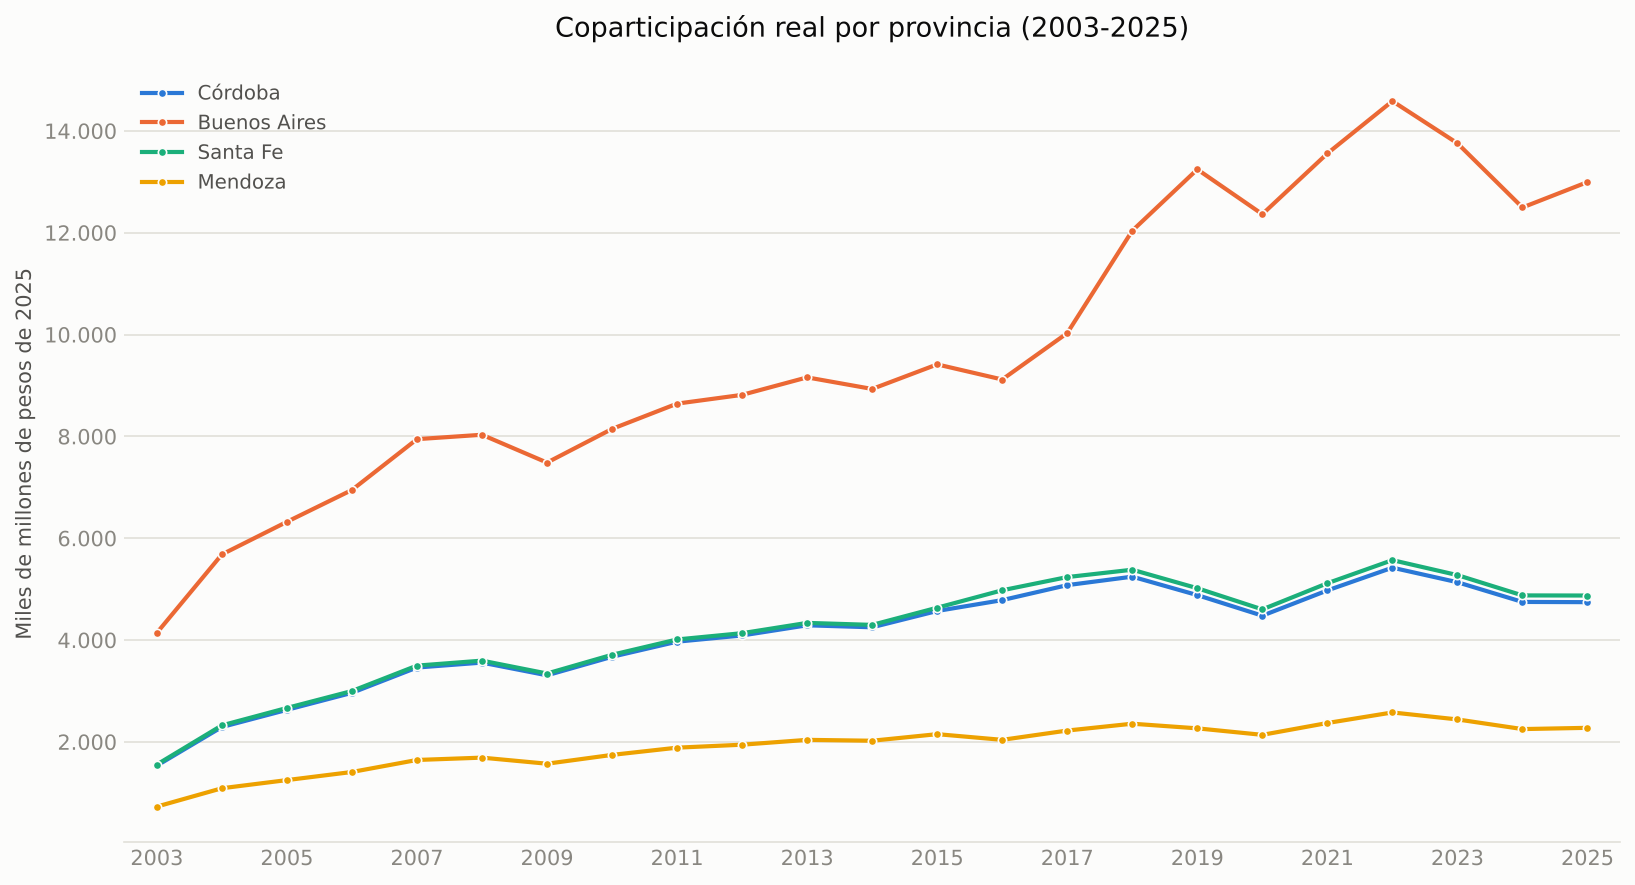

In [4]:
provincias_referencia = ["Córdoba", "Buenos Aires", "Santa Fe", "Mendoza"]
colores = {
    "Córdoba": COLOR_CORDOBA,
    "Buenos Aires": COLOR_BUENOS_AIRES,
    "Santa Fe": COLOR_SANTA_FE,
    "Mendoza": COLOR_MENDOZA,
}

fig, ax = plt.subplots(figsize=(11, 6), dpi=150)
for provincia in provincias_referencia:
    serie = df[df["provincia"] == provincia].sort_values("anio")
    ax.plot(
        serie["anio"], serie["real_miles_millones_2025"],
        color=colores[provincia], linewidth=2, marker="o", markersize=4,
        markerfacecolor=colores[provincia], markeredgecolor=SURFACE, markeredgewidth=0.8,
        label=provincia,
    )

ax.set_title("Coparticipación real por provincia (2003-2025)", fontsize=13, color=INK_PRIMARY, pad=14)
ax.set_ylabel("Miles de millones de pesos de 2025", fontsize=10)
ax.set_xlabel("")
ax.set_xlim(2002.5, 2025.5)
ax.set_xticks(range(2003, 2026, 2))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", ".")))
ax.grid(axis="y", color=GRID_COLOR, linewidth=0.8)
ax.set_axisbelow(True)
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_color(GRID_COLOR)
ax.tick_params(axis="both", length=0)
legend = ax.legend(frameon=False, loc="upper left", fontsize=9.5)
for text in legend.get_texts():
    text.set_color(INK_SECONDARY)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "comparativo_provincias_real_2003_2025.png", dpi=300, facecolor=SURFACE)
plt.show()

## 4. Por habitante: Córdoba vs. provincias de referencia

Para comparar provincias de distinto tamaño no hace falta elegir un año base: alcanza
con dividir por la población. Uso la población de cada año interpolada entre los censos
2001, 2010 y 2022 de INDEC (`scripts/poblacion.py`; después de 2022 extiendo la tasa de
crecimiento 2010-2022 de cada provincia). El método y sus supuestos están en
`docs/methodology.md`.

Antes había acá un índice 2003 = 100. Lo saqué porque el resultado dependía del año
base: 2003 es el piso de la crisis, y con base 2004 el orden entre las provincias
cambiaba (Buenos Aires, que en 2004 todavía tenía el Fondo del Conurbano congelado,
pasaba a ser la que más crecía).

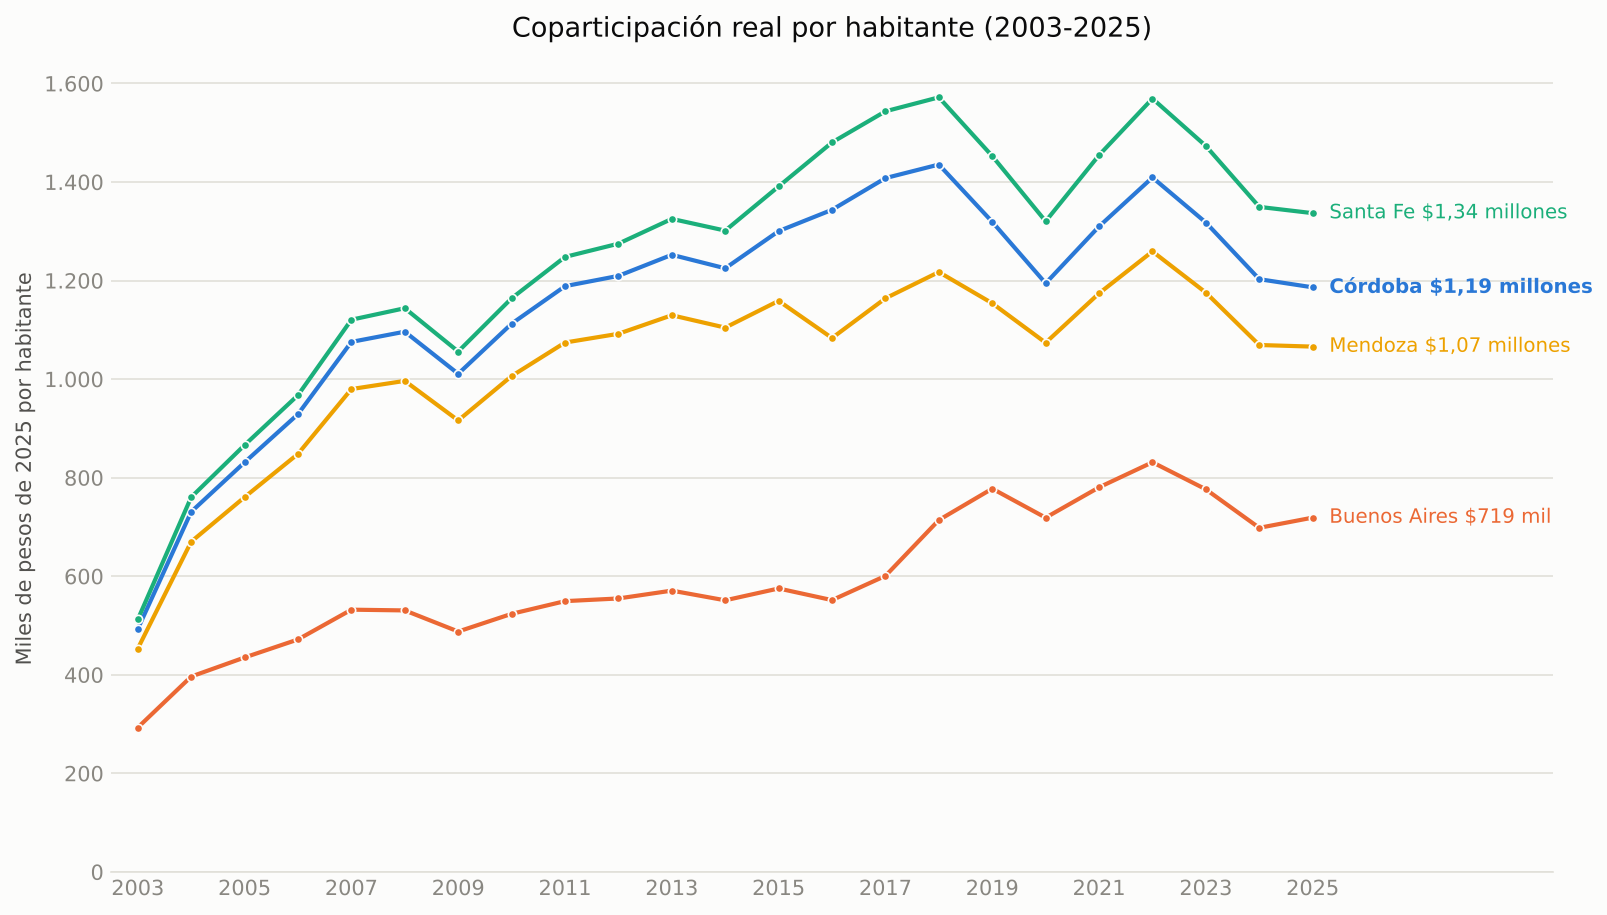

Por habitante, 2025 / 2004: Córdoba x1,62, Buenos Aires x1,81, Santa Fe x1,76, Mendoza x1,59


In [5]:
ph = por_habitante.pivot(index="anio", columns="provincia", values="por_habitante_pesos_2025") / 1e3

fig, ax = plt.subplots(figsize=(11, 6.2), dpi=150)
for provincia in provincias_referencia:
    ax.plot(
        ph.index, ph[provincia],
        color=colores[provincia], linewidth=2, marker="o", markersize=4,
        markerfacecolor=colores[provincia], markeredgecolor=SURFACE, markeredgewidth=0.8,
    )
    ax.annotate(
        f"{provincia} {pesos_por_habitante(ph.loc[2025, provincia])}",
        (2025, ph.loc[2025, provincia]), xytext=(8, 0), textcoords="offset points",
        ha="left", va="center", fontsize=9.5, color=colores[provincia],
        fontweight=("bold" if provincia == "Córdoba" else "normal"),
    )

ax.set_title("Coparticipación real por habitante (2003-2025)", fontsize=13, color=INK_PRIMARY, pad=14)
ax.set_ylabel("Miles de pesos de 2025 por habitante", fontsize=10)
ax.set_xlabel("")
ax.set_xlim(2002.5, 2029.5)
ax.set_xticks(range(2003, 2026, 2))
ax.set_ylim(0, None)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", ".")))
ax.grid(axis="y", color=GRID_COLOR, linewidth=0.8)
ax.set_axisbelow(True)
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_color(GRID_COLOR)
ax.tick_params(axis="both", length=0)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "comparativo_provincias_por_habitante_2003_2025.png", dpi=300, facecolor=SURFACE)
plt.show()

crecimiento = (ph.loc[2025] / ph.loc[2004])[provincias_referencia]
print("Por habitante, 2025 / 2004:", ", ".join(f"{p} x{ar(v)}" for p, v in crecimiento.items()))

Por habitante, el orden es otro que en niveles. En 2025, Santa Fe recibió unos \$1,34
millones por habitante (en pesos de 2025), Córdoba \$1,19 millones, Mendoza \$1,07
millones y Buenos Aires \$719 mil: la provincia que más recibe en total es la que menos
recibe por persona.

Las trayectorias se parecen, pero no son iguales. Desde 2004, la coparticipación por
habitante de Córdoba creció 1,62 veces, contra 1,76 en Santa Fe. En monto total las dos
crecieron casi lo mismo; la diferencia es que la población de Córdoba creció más (27%
contra 19%), así que el mismo aumento se reparte entre más gente. Buenos Aires creció 1,81
veces porque en 2004 su Fondo del Conurbano estaba congelado y lo recuperó con el
Consenso Fiscal; Mendoza, 1,59.

Por habitante, el máximo de Córdoba no fue 2022 sino 2018 (\$1,44 millones), y 2025
queda 17% por debajo. El Núcleo 5 hace esta comparación para las 24 jurisdicciones.

## 5. ¿Es mucho o poco? Por habitante y como % del PIB

Que la coparticipación real de 2025 sea 3,1 veces la de 2003 no dice si creció más o
menos que la población o que la economía. Acá pongo el total de las 24 jurisdicciones
contra las dos cosas. El PIB es el del INDEC (año base 2004), que arranca en 2004, así
que el porcentaje del PIB cubre 2004-2025.

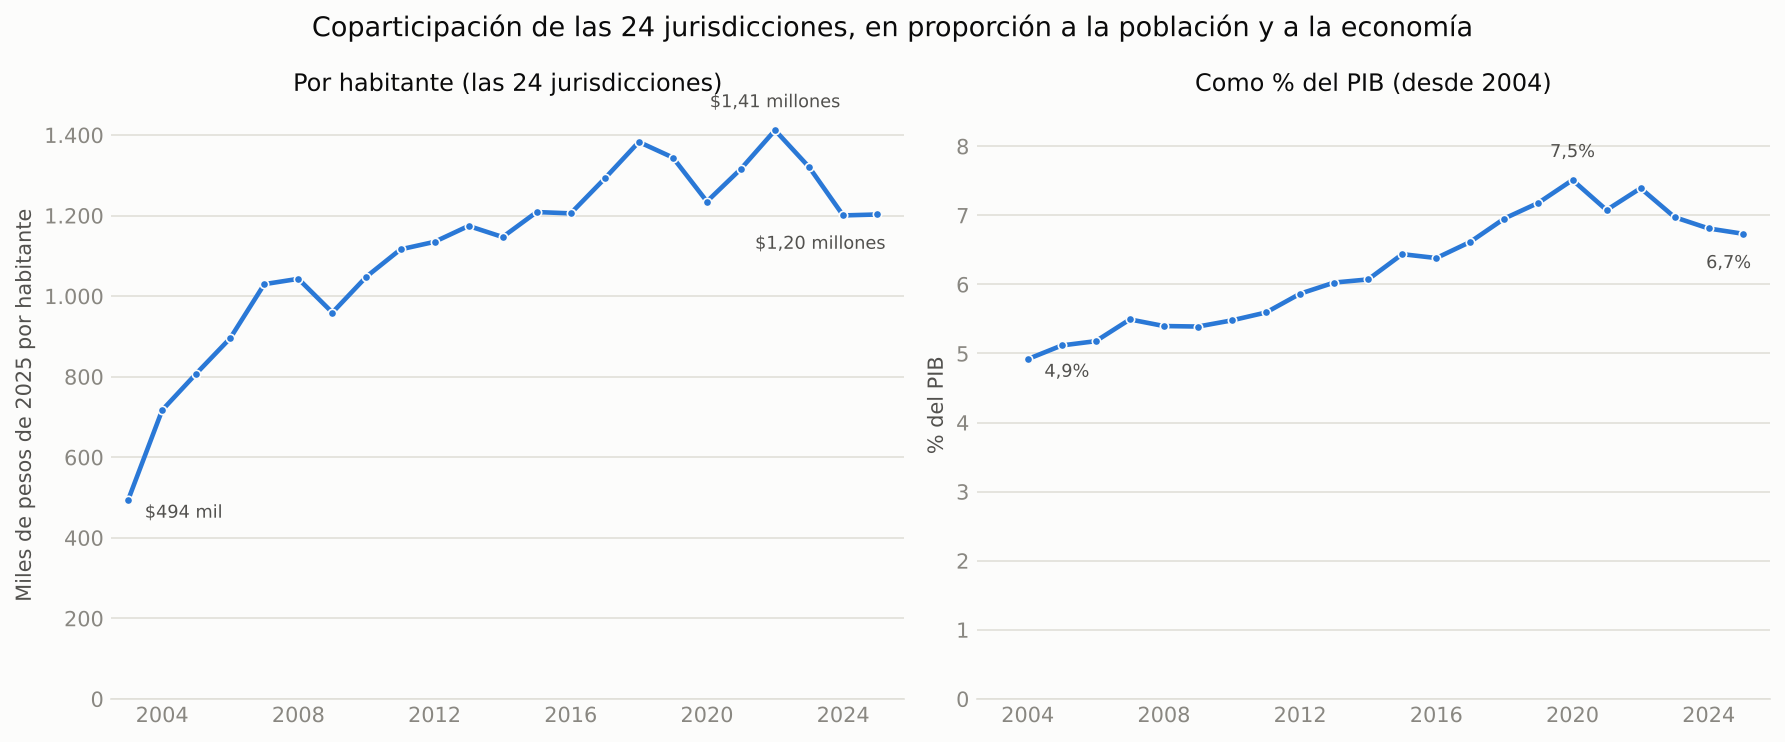

In [6]:
a = agregada.set_index("anio")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), dpi=150)
serie_ph = a["por_habitante_pesos_2025"] / 1e3
ax1.plot(serie_ph.index, serie_ph, color=COLOR_CORDOBA, linewidth=2.2, marker="o", markersize=4,
         markerfacecolor=COLOR_CORDOBA, markeredgecolor=SURFACE, markeredgewidth=0.8)
ax1.set_title("Por habitante (las 24 jurisdicciones)", fontsize=11.5, color=INK_PRIMARY, pad=10)
ax1.set_ylabel("Miles de pesos de 2025 por habitante", fontsize=10)
ax1.set_ylim(0, None)

serie_pib = a["coparticipacion_pct_pib"].dropna()
ax2.plot(serie_pib.index, serie_pib, color=COLOR_CORDOBA, linewidth=2.2, marker="o", markersize=4,
         markerfacecolor=COLOR_CORDOBA, markeredgecolor=SURFACE, markeredgewidth=0.8)
ax2.set_title("Como % del PIB (desde 2004)", fontsize=11.5, color=INK_PRIMARY, pad=10)
ax2.set_ylabel("% del PIB", fontsize=10)
ax2.set_ylim(0, 8.5)

for ax, serie, fmt in [
    (ax1, serie_ph, pesos_por_habitante),
    (ax2, serie_pib, lambda v: f"{ar(v, 1)}%"),
]:
    for anio in sorted({serie.index[0], serie.idxmax(), serie.index[-1]}):
        # El primero va a la derecha del punto y el último debajo, para no pisar la línea.
        primero, ultimo = anio == serie.index[0], anio == serie.index[-1]
        ax.annotate(fmt(serie.loc[anio]), (anio, serie.loc[anio]),
                    xytext=((8, -2) if primero else (4, -10) if ultimo else (0, 9)), textcoords="offset points",
                    ha=("left" if primero else "right" if ultimo else "center"),
                    va=("top" if primero or ultimo else "bottom"), fontsize=8.5, color=INK_SECONDARY)
    ax.set_xlim(2002.5, 2025.8)
    ax.set_xticks(range(2004, 2026, 4))
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: ar(x, 0)))
    ax.grid(axis="y", color=GRID_COLOR, linewidth=0.8)
    ax.set_axisbelow(True)
    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)
    ax.spines["bottom"].set_color(GRID_COLOR)
    ax.tick_params(axis="both", length=0)

fig.suptitle("Coparticipación de las 24 jurisdicciones, en proporción a la población y a la economía",
             fontsize=13, color=INK_PRIMARY)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "coparticipacion_por_habitante_y_pct_pib.png", dpi=300, facecolor=SURFACE)
plt.show()

Por habitante, la coparticipación real de las 24 jurisdicciones pasó de \$494 mil en
2003 y \$717 mil en 2004 a un máximo de \$1,41 millones en 2022 (pesos de 2025), y cerró
2025 en \$1,20 millones: 15% menos que en 2022 y prácticamente lo mismo que en 2016.
Desde 2004 creció 1,68 veces, bastante menos que el 2,14 del monto total, porque la
población creció 27%.

Como porcentaje del PIB pasó de 4,9% en 2004 a 6,7% en 2025, con un máximo de 7,5% en
2020 (ese año el PIB cayó más que la recaudación coparticipable). O sea que creció más
que la economía, y la descomposición de abajo muestra por qué.

In [7]:
factores = descomponer(agregada, 2004, 2025)
factores["multiplicador_2004_2025"].map(lambda v: f"x{ar(v, 3)}").to_frame()

,multiplicador_2004_2025
factor,
PIB real,"x1,525"
Deflactor del PIB / IPC,"x1,024"
Masa Ley 23.548 / PIB,"x1,258"
Parte de la masa que llega a las 24,"x1,089"
Coparticipación real (total),"x2,139"
Población,"x1,275"
Coparticipación real por habitante,"x1,678"


Entre 2004 y 2025, la coparticipación real de las 24 se multiplicó por 2,14, y la
identidad lo reparte así:

- **PIB real: ×1,53.** Es lo que creció la economía. Por sí solo explica algo más de la
  mitad del crecimiento (en logaritmos, el 56%).
- **Deflactor del PIB contra IPC: ×1,02.** Casi neutro. Deflactar por IPC o por el
  deflactor del PIB da prácticamente lo mismo (×2,14 contra ×2,09), así que el resultado
  no depende del índice de precios elegido.
- **Masa de la Ley 23.548 sobre el PIB: ×1,26.** Los impuestos que se coparticipan
  recaudan más en relación al tamaño de la economía: de 8,7% a 11,0% del PIB. Parte es
  presión tributaria; parte es reclasificación, porque desde 2018 las asignaciones
  específicas de Ganancias entran por la Ley 23.548 (ese año la masa pasa de 10,4% a
  11,8% del PIB).
- **Parte de la masa que llega a las 24: ×1,09.** Dentro de la Ley 23.548, la porción de
  las provincias pasó de 48% a 59% entre 2004 y 2025, sobre todo por la devolución del
  15% que se detraía para la ANSES (2016-2020). El factor queda en ×1,09 y no en ×1,22
  porque, con la definición de este núcleo, antes de 2018 las provincias recibían las
  asignaciones de Ganancias por fuera de la masa, y desde 2018 por dentro.

Juntos, los dos últimos factores son el paso de 4,9% a 6,7% del PIB (×1,37): reglas que
le dieron a las provincias una parte más grande de una recaudación que, además, creció
más que la economía. Dividiendo por la población (×1,28), queda el ×1,68 por
habitante.

## 6. Conclusiones y próximos pasos

- La coparticipación real de Córdoba en 2025 es 3,1 veces la de 2003, pero ese número
  exagera: 2003 es el piso de la crisis. Contra 2004 es 2,1 veces, y por habitante, 1,6
  veces. Por habitante, Córdoba tuvo su máximo en 2018 y en 2025 está 17% por debajo.
- Para las 24 jurisdicciones juntas, la coparticipación por habitante creció 1,68 veces
  desde 2004 y cerró 2025 en el nivel de 2016. Como % del PIB pasó de 4,9% a 6,7%: creció
  con la economía (×1,53), con una recaudación coparticipable más alta en relación al PIB
  y con la devolución del 15% de la ANSES. No hay ilusión monetaria en la serie: con el
  deflactor del PIB en vez del IPC, el resultado es casi el mismo.
- Por habitante, Buenos Aires recibe mucho menos que Córdoba, Santa Fe y Mendoza. Entre
  Córdoba y Santa Fe, que en monto total crecieron casi igual, la diferencia por habitante
  sale de que la población de Córdoba creció más.
- Limitaciones a tener en cuenta (con el detalle completo en `docs/methodology.md`):
  - El rango 2003-2025 depende, para 2003-2015, de un IPC empalmado con una fuente
    privada (Fundación Norte y Sur / Orlando Ferreres) para el tramo 2007-2015, porque
    el IPC oficial de esos años quedó desacreditado por la intervención del INDEC. Esa
    fuente tiene además una limitación propia que no pude resolver: no logré verificar
    el contenido exacto de su nota "Ver metodología". Además, el IPC oficial
    actual arranca en diciembre de 2016, así que el promedio de 2016 lo estimo a partir
    del promedio oficial de 2017 y la variación 2017 de esa misma fuente privada.
  - No llega a 1990 porque no hay una fuente de montos nominales de coparticipación
    por provincia anterior a 2003.
  - La definición de "coparticipación" que uso excluye otros regímenes de Recursos de
    Origen Nacional (IVA de la Ley 23.966, Bienes Personales, combustibles, etc.).
  - La población entre censos es una interpolación, y la de 2023-2025 extiende la tasa
    2010-2022; con la caída de la natalidad, probablemente esté algo sobreestimada, y la
    coparticipación por habitante de esos años, algo subestimada.
  - El PIB del INDEC arranca en 2004, así que el % del PIB y la descomposición no
    cubren 2003.